# 03 — MEWMA Control Chart (Layer 1)
## Smart Dormitory IoT Anomaly Detection

**Tujuan**: Mengimplementasikan Multivariate Exponentially Weighted Moving Average (MEWMA) control chart sebagai Layer 1 deteksi anomali. MEWMA diaplikasikan pada PCA-reduced data (27 komponen) untuk mendeteksi pergeseran statistik multivariate.

**Referensi**: Lowry, C.A. et al. (1992). "A Multivariate Exponentially Weighted Moving Average Control Chart." *Technometrics*, 34(1), 46–53.

### Config & load preprocessed data
**Tujuan**: Load artefak dari `02_preprocessing`.
**Input**: Files di `/content/preprocessed/`.
**Output**: PCA data, labels, metadata.

In [3]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [6]:
import sys
import json
import pickle
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# === CONFIG ===
SEED = 42
DATA_PATH = "/content/Smart_Dormitory_CLEAN_2025-11-01_to_2026-06-30.csv"
FIGURE_DIR = "/content/figures"
RESULTS_DIR = "/content/results"
TIMESTAMP_COL = "timestamp"
TRAIN_END = "2026-03-31 23:30:00"
WINDOW_SIZE = 48
N_PCA = 27

Path(FIGURE_DIR).mkdir(parents=True, exist_ok=True)
Path(RESULTS_DIR).mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 300,
    "figure.figsize": (12, 5),
    "axes.titlesize": 13, "axes.labelsize": 11,
    "axes.grid": True, "grid.alpha": 0.3,
})

# === BOOTSTRAP: Rebuild preprocessing ===
print("Bootstrapping preprocessing...")

# 1. Load raw
df_raw = pd.read_csv(DATA_PATH, parse_dates=[TIMESTAMP_COL])

# 2. Build anomaly tier labels
log_cols = [c for c in df_raw.columns if c.endswith("_log_level") and c != "command_log_level"]
critical_events = [
    "FIRE_EVENT_CONFIRMED", "LEAK_DETECTED_VALVE_CLOSED",
    "PANIC_BUTTON_ACTIVATED", "EMERGENCY_ACCESS_MODE",
    "RESTRICTED_AREA_INTRUSION", "VISUAL_FIRE_DETECTED",
]
event_cols = [c for c in df_raw.columns if c.endswith("_event") and c != "command_event"]

def classify_tier(row):
    for ec in event_cols:
        if row[ec] in critical_events:
            return "CRITICAL"
    n_warn = sum(1 for c in log_cols if row[c] != "INFO")
    if n_warn >= 2:
        return "MULTI_NODE_WARNING"
    if n_warn == 1:
        return "SINGLE_NODE_WARNING"
    return "NORMAL"

df_raw["anomaly_tier"] = df_raw.apply(classify_tier, axis=1)
df_labels = df_raw[[TIMESTAMP_COL, "is_anomaly_proxy", "anomaly_severity_proxy", "anomaly_tier"]].copy()

# 3. Drop columns
drop_cols = [
    "is_anomaly_proxy", "anomaly_severity_proxy",
    "command_active_alerts", "command_log_level", "command_event", "command_workflow",
    "node03_energy_cumulative_kwh", "node04_water_cumulative_l",
    "node03_energy_interval_kwh", "node04_water_interval_l", "node03_current_a",
    "interval_id", "anomaly_tier",
]
df = df_raw.drop(columns=drop_cols)

# 4. Encode categoricals
binary_map = {
    "ON": 1, "OFF": 0, "OPEN": 1, "CLOSED": 0,
    "LOCKED": 1, "UNLOCKED": 0, "AVAILABLE": 1, "USED": 0,
    "RUNNING": 1, "READY": 1, "BUSY": 1, "TONER_LOW": 0,
    "CONNECTED": 1, "RECONNECTING": 0,
}
log_map = {"INFO": 0, "WARNING": 1, "CRITICAL": 2}

binary_cols = [
    "node01_ac_status", "node01_fan_status", "node02_siren", "node02_emergency_light",
    "node03_light_status", "node03_outlet_status", "node04_pump_status", "node04_valve_status",
    "node05_door_status", "node05_lock_status", "node05_emergency_mode",
    "node06_locker01_status", "node06_locker02_status", "node06_laundry01_status",
    "node06_printer_status", "mqtt_status",
]
for col in binary_cols:
    df[col] = df[col].map(binary_map)

log_level_cols = [c for c in df.columns if c.endswith("_log_level")]
for col in log_level_cols:
    df[col] = df[col].map(log_map)

event_cols_drop = [c for c in df.columns if c.endswith("_event")]
df = df.drop(columns=event_cols_drop)

# 5. Temporal features
df["hour_sin"] = np.sin(2 * np.pi * df[TIMESTAMP_COL].dt.hour / 24)
df["hour_cos"] = np.cos(2 * np.pi * df[TIMESTAMP_COL].dt.hour / 24)
df["dow_sin"] = np.sin(2 * np.pi * df[TIMESTAMP_COL].dt.dayofweek / 7)
df["dow_cos"] = np.cos(2 * np.pi * df[TIMESTAMP_COL].dt.dayofweek / 7)

feature_cols = [c for c in df.columns if c != TIMESTAMP_COL]

# 6. Temporal split
train_mask = df[TIMESTAMP_COL] <= TRAIN_END
test_mask = ~train_mask
labels_train = df_labels[train_mask].reset_index(drop=True)
labels_test = df_labels[test_mask].reset_index(drop=True)

# 7. StandardScaler fit on NORMAL training only
normal_mask = labels_train["anomaly_tier"] == "NORMAL"
X_train_all = df.loc[train_mask, feature_cols].values
X_test_all = df.loc[test_mask, feature_cols].values
X_train_normal = df.loc[train_mask, feature_cols].values[normal_mask.values]

scaler = StandardScaler()
scaler.fit(X_train_normal)
X_train_std = scaler.transform(X_train_normal)
X_test_std = scaler.transform(X_test_all)

# 8. PCA fit on NORMAL training only
pca = PCA(n_components=N_PCA, random_state=SEED)
pca.fit(X_train_std)
X_train_pca = pca.transform(X_train_std)
X_test_pca = pca.transform(X_test_std)

print(f"Execution date: {datetime.now().strftime('%Y-%m-%d %H:%M')}")
print(f"X_train_pca (NORMAL only): {X_train_pca.shape}")
print(f"X_test_pca: {X_test_pca.shape}")
print(f"PCA variance retained: {pca.explained_variance_ratio_.sum()*100:.1f}%")
print(f"Features: {len(feature_cols)}")

# === Assertions ===
assert X_train_pca.shape == (normal_mask.sum(), N_PCA)
assert X_test_pca.shape[0] == labels_test.shape[0]
assert not np.isnan(X_train_pca).any()
assert not np.isnan(X_test_pca).any()

print(f"\n✓ Bootstrap complete. Ready for MEWMA.")

Bootstrapping preprocessing...
Execution date: 2026-09-01 11:47
X_train_pca (NORMAL only): (4201, 27)
X_test_pca: (4368, 27)
PCA variance retained: 95.9%
Features: 61

✓ Bootstrap complete. Ready for MEWMA.


### MEWMA implementation
**Tujuan**: Mengimplementasikan MEWMA control chart. MEWMA menghitung statistik T² dari vektor EWMA multivariate. Smoothing parameter λ dan control limit h ditentukan berdasarkan data training NORMAL — h ditetapkan dari persentil distribusi T² training agar menghasilkan FPR yang terkontrol.

**Referensi**: Lowry et al. (1992), Technometrics 34(1).

**Input**: `X_train_pca`, `X_test_pca`.
**Output**: MEWMA T² scores untuk train dan test, control limit h.

In [8]:
class MEWMA:
    """Multivariate Exponentially Weighted Moving Average control chart.

    Parameters
    ----------
    lambda_ : float
        Smoothing parameter (0 < lambda_ <= 1). Smaller values detect
        smaller shifts but respond slower. Typical range: 0.05–0.30.
    """

    def __init__(self, lambda_=0.10):
        self.lambda_ = lambda_
        self.mu_ = None          # in-control mean vector
        self.sigma_inv_ = None   # inverse of in-control covariance
        self.h_ = None           # control limit

    def fit(self, X_train, fpr_target=0.05):
        """Fit MEWMA on in-control (NORMAL) training data.

        Parameters
        ----------
        X_train : ndarray of shape (n, p)
            In-control training data (PCA-transformed, standardized).
        fpr_target : float
            Target false positive rate on training data to set control limit.
        """
        self.mu_ = X_train.mean(axis=0)
        cov = np.cov(X_train, rowvar=False)

        # Regularize covariance for numerical stability
        cov += np.eye(cov.shape[0]) * 1e-6
        self.sigma_inv_ = np.linalg.inv(cov)

        # Compute T² on training data to set control limit
        t2_train = self._compute_t2(X_train)
        self.h_ = np.percentile(t2_train, (1 - fpr_target) * 100)

        return t2_train

    def score(self, X):
        """Compute MEWMA T² statistics for new data.

        Parameters
        ----------
        X : ndarray of shape (n, p)

        Returns
        -------
        t2 : ndarray of shape (n,)
            MEWMA T² statistic at each time step.
        """
        return self._compute_t2(X)

    def predict(self, X):
        """Predict anomaly (1) or normal (0) based on control limit.

        Returns
        -------
        preds : ndarray of shape (n,)
        """
        t2 = self.score(X)
        return (t2 > self.h_).astype(int)

    def _compute_t2(self, X):
        """Compute MEWMA T² statistics."""
        n, p = X.shape
        lam = self.lambda_

        # EWMA covariance matrix (exact, Lowry et al. 1992 eq. 3)
        # sigma_z = (lambda / (2 - lambda)) * sigma_x
        # For the asymptotic case (large n), this simplifies
        sigma_z = (lam / (2 - lam)) * np.linalg.inv(self.sigma_inv_)
        sigma_z_inv = np.linalg.inv(sigma_z + np.eye(p) * 1e-8)

        t2 = np.zeros(n)
        z = np.zeros(p)  # initialize EWMA vector at zero (= centered mean)

        for i in range(n):
            x_centered = X[i] - self.mu_
            z = lam * x_centered + (1 - lam) * z
            t2[i] = z @ sigma_z_inv @ z

        return t2


# === Fit MEWMA ===
# Test multiple lambda values
lambdas = [0.05, 0.10, 0.15, 0.20, 0.30]
fpr_target = 0.05

print(f"=== MEWMA fitting (FPR target: {fpr_target}) ===\n")

mewma_results = {}
for lam in lambdas:
    model = MEWMA(lambda_=lam)
    t2_train = model.fit(X_train_pca, fpr_target=fpr_target)
    t2_test = model.score(X_test_pca)
    preds_test = model.predict(X_test_pca)

    # Actual FPR on test NORMAL data
    test_normal_mask = labels_test["anomaly_tier"].values == "NORMAL"
    fpr_actual = preds_test[test_normal_mask].mean()

    # Detection rate per tier
    tiers = ["SINGLE_NODE_WARNING", "MULTI_NODE_WARNING", "CRITICAL"]
    detection_rates = {}
    for tier in tiers:
        tier_mask = labels_test["anomaly_tier"].values == tier
        if tier_mask.sum() > 0:
            detection_rates[tier] = preds_test[tier_mask].mean()

    mewma_results[lam] = {
        "model": model,
        "t2_train": t2_train,
        "t2_test": t2_test,
        "preds_test": preds_test,
        "h": model.h_,
        "fpr_actual": fpr_actual,
        "detection_rates": detection_rates,
    }

    print(f"λ={lam:.2f} | h={model.h_:.2f} | FPR={fpr_actual:.3f} | "
          f"SINGLE={detection_rates.get('SINGLE_NODE_WARNING',0):.3f} | "
          f"MULTI={detection_rates.get('MULTI_NODE_WARNING',0):.3f} | "
          f"CRITICAL={detection_rates.get('CRITICAL',0):.3f}")

print(f"\n✓ MEWMA fitted with {len(lambdas)} lambda values.")

=== MEWMA fitting (FPR target: 0.05) ===

λ=0.05 | h=333.10 | FPR=0.126 | SINGLE=0.131 | MULTI=0.104 | CRITICAL=0.000
λ=0.10 | h=199.71 | FPR=0.127 | SINGLE=0.159 | MULTI=0.179 | CRITICAL=0.167
λ=0.15 | h=145.21 | FPR=0.127 | SINGLE=0.200 | MULTI=0.289 | CRITICAL=0.167
λ=0.20 | h=117.05 | FPR=0.122 | SINGLE=0.225 | MULTI=0.335 | CRITICAL=0.167
λ=0.30 | h=86.22 | FPR=0.103 | SINGLE=0.254 | MULTI=0.410 | CRITICAL=0.167

✓ MEWMA fitted with 5 lambda values.


### MEWMA lambda selection & control chart visualization
**Tujuan**: Memilih lambda optimal berdasarkan keseimbangan detection rate vs FPR, lalu memvisualisasikan MEWMA T² control chart pada data test.
**Input**: `mewma_results`.
**Output**: Lambda terpilih, control chart plot disimpan sebagai `fig_08_mewma_chart.png`.

Selected λ = 0.3
  Control limit h = 86.22
  FPR = 0.103
  Detection rates: {'SINGLE_NODE_WARNING': np.float64(0.25396825396825395), 'MULTI_NODE_WARNING': np.float64(0.41040462427745666), 'CRITICAL': np.float64(0.16666666666666666)}


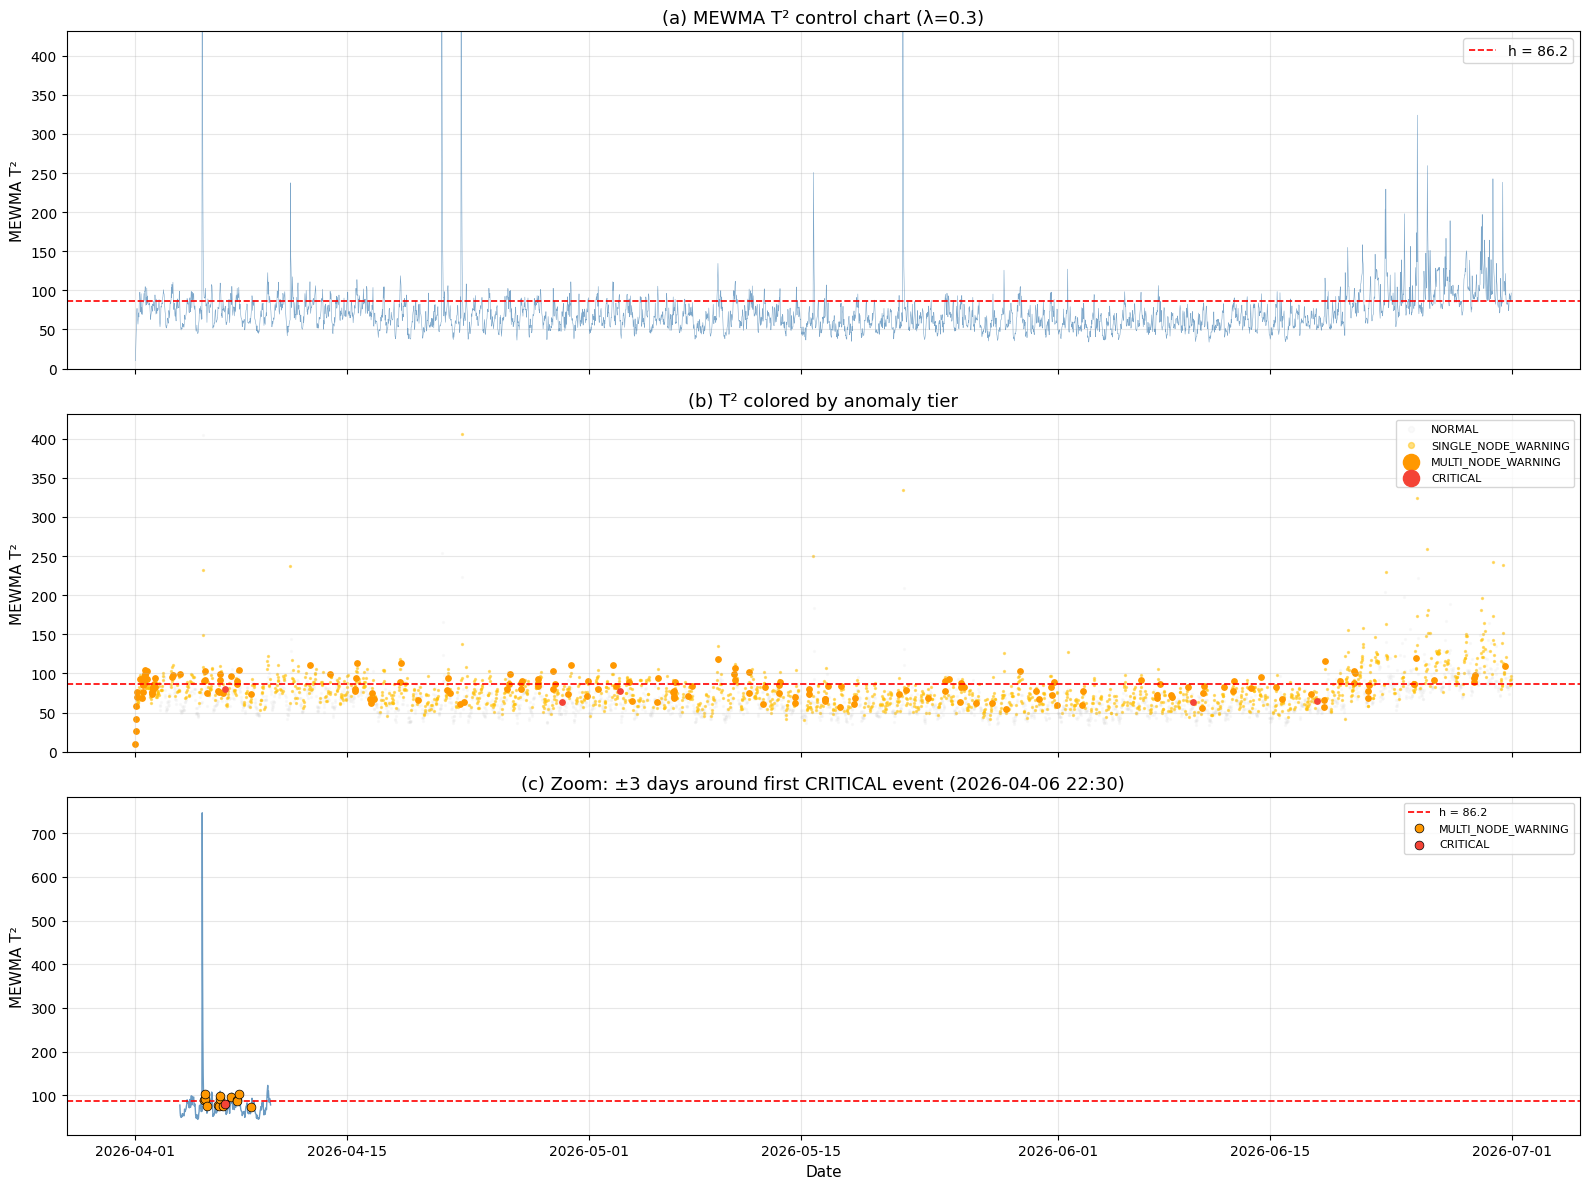


✓ MEWMA results saved. λ=0.3, h=86.22


In [9]:
# Select best lambda: maximize average detection rate across tiers
# while keeping FPR reasonable
best_lam = None
best_score = -1

for lam, res in mewma_results.items():
    dr = res["detection_rates"]
    # Weighted average: CRITICAL matters most
    avg_dr = (
        dr.get("SINGLE_NODE_WARNING", 0) * 0.2 +
        dr.get("MULTI_NODE_WARNING", 0) * 0.3 +
        dr.get("CRITICAL", 0) * 0.5
    )
    # Penalize high FPR
    score = avg_dr - 0.5 * max(0, res["fpr_actual"] - 0.10)
    if score > best_score:
        best_score = score
        best_lam = lam

print(f"Selected λ = {best_lam}")
mewma_best = mewma_results[best_lam]
print(f"  Control limit h = {mewma_best['h']:.2f}")
print(f"  FPR = {mewma_best['fpr_actual']:.3f}")
print(f"  Detection rates: {mewma_best['detection_rates']}")

# === Control chart visualization ===
t2_test = mewma_best["t2_test"]
h = mewma_best["h"]
test_timestamps = pd.to_datetime(labels_test[TIMESTAMP_COL])

fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)

# (a) Full T² timeline
ax = axes[0]
ax.plot(test_timestamps, t2_test, linewidth=0.4, color="steelblue", alpha=0.7)
ax.axhline(y=h, color="red", linestyle="--", linewidth=1.2, label=f"h = {h:.1f}")
ax.set_ylabel("MEWMA T²")
ax.set_title(f"(a) MEWMA T² control chart (λ={best_lam})")
ax.legend(loc="upper right")
ax.set_ylim(0, min(t2_test.max() * 1.1, h * 5))

# (b) T² with anomaly tier overlay
ax = axes[1]
tier_colors = {
    "NORMAL": "lightgray",
    "SINGLE_NODE_WARNING": "#FFC107",
    "MULTI_NODE_WARNING": "#FF9800",
    "CRITICAL": "#F44336",
}
for tier in ["NORMAL", "SINGLE_NODE_WARNING", "MULTI_NODE_WARNING", "CRITICAL"]:
    mask = labels_test["anomaly_tier"].values == tier
    alpha = 0.1 if tier == "NORMAL" else (0.5 if tier == "SINGLE_NODE_WARNING" else 1.0)
    size = 2 if tier in ["NORMAL", "SINGLE_NODE_WARNING"] else 15
    ax.scatter(test_timestamps[mask], t2_test[mask],
               s=size, alpha=alpha, color=tier_colors[tier], label=tier)

ax.axhline(y=h, color="red", linestyle="--", linewidth=1.2)
ax.set_ylabel("MEWMA T²")
ax.set_title("(b) T² colored by anomaly tier")
ax.legend(fontsize=8, markerscale=3, loc="upper right")
ax.set_ylim(0, min(t2_test.max() * 1.1, h * 5))

# (c) Zoom into a week with CRITICAL event
critical_mask = labels_test["anomaly_tier"].values == "CRITICAL"
if critical_mask.any():
    first_critical_idx = np.where(critical_mask)[0][0]
    center_time = test_timestamps.iloc[first_critical_idx]
    zoom_start = center_time - pd.Timedelta(days=3)
    zoom_end = center_time + pd.Timedelta(days=3)
    zoom_mask = (test_timestamps >= zoom_start) & (test_timestamps <= zoom_end)

    ax = axes[2]
    ax.plot(test_timestamps[zoom_mask], t2_test[zoom_mask],
            linewidth=1, color="steelblue", alpha=0.8)
    ax.axhline(y=h, color="red", linestyle="--", linewidth=1.2, label=f"h = {h:.1f}")

    for tier in ["MULTI_NODE_WARNING", "CRITICAL"]:
        tier_mask = (labels_test["anomaly_tier"].values == tier) & zoom_mask.values
        if tier_mask.any():
            ax.scatter(test_timestamps[tier_mask], t2_test[tier_mask],
                       s=40, color=tier_colors[tier], zorder=5, label=tier, edgecolors="black", linewidth=0.5)

    ax.set_ylabel("MEWMA T²")
    ax.set_xlabel("Date")
    ax.set_title(f"(c) Zoom: ±3 days around first CRITICAL event ({center_time.strftime('%Y-%m-%d %H:%M')})")
    ax.legend(fontsize=8, loc="upper right")

fig.tight_layout()
fig.savefig(f"{FIGURE_DIR}/fig_08_mewma_chart.png", bbox_inches="tight")
plt.show()

# Save MEWMA scores for fusion later
np.savez_compressed(
    f"{RESULTS_DIR}/mewma_scores.npz",
    t2_test=t2_test,
    h=np.array([h]),
    lambda_=np.array([best_lam]),
    preds_test=mewma_best["preds_test"],
)

print(f"\n✓ MEWMA results saved. λ={best_lam}, h={h:.2f}")